<a href="https://colab.research.google.com/github/Shlok-11/Stock-Price-Predictor/blob/main/Final_code_lstm_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import neccessary libraries

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import RootMeanSquaredError, MeanAbsoluteError

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit



import warnings
warnings.filterwarnings('ignore')

--------------
Data taken from 2019-2009 (20 Year Period)

2020 will only be presented once testing is finalized.

In [ ]:
#Downloading of data from Yahoo Finance which will be used for model training
end = '2019-12-31'
start = '1999-01-02'

trainingData = yf.download('NVDA', start=start, end=end)
trainingData.head()
trainingData.shape


[*********************100%***********************]  1 of 1 completed


(5269, 5)

In [ ]:
#Downloading of data from Yahoo Finance which will be used for model testing
end = '2024-01-31'
start = '2020-01-02'

testingData = yf.download('NVDA', start=start, end=end)
testingData.head()
testingData.shape

[*********************100%***********************]  1 of 1 completed


(1026, 5)

In [ ]:
#Prediction will take place on Adj Close price, therefore we must isolate Adj Close.
trainprice = trainingData['Close']
trainData = trainprice.values

testprice = testingData['Close']
testData = testprice.values

In [ ]:
trainData


array([1228.09997559, 1244.7800293 , 1272.33996582, ..., 3239.90991211,
       3240.02001953, 3221.29003906])

Plotting of High vs Low

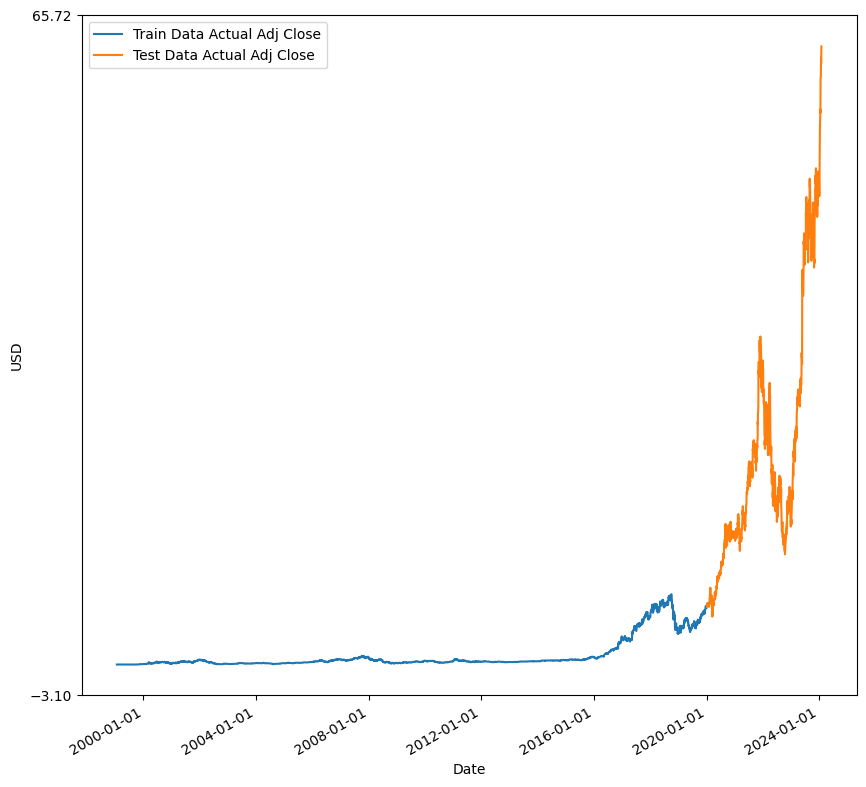

In [ ]:
plt.figure(figsize=(10,10))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().yaxis.set_major_locator(mdates.DayLocator(interval=200))

plt.plot(trainingData.index, trainingData['Close'], label='Train Data Actual Adj Close')
plt.plot(testingData.index, testingData['Close'], label='Test Data Actual Adj Close')
plt.xlabel('Date')
plt.ylabel('USD')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

In [ ]:
sc = MinMaxScaler(feature_range=(0,1))
trainDataScaled = sc.fit_transform(trainData.reshape(-1, 1))
testDataScaled = sc.fit_transform(testData.reshape(-1, 1))

In [ ]:
n_steps = 20

xTrain, yTrain = [], []

for i in range(n_steps, len(trainDataScaled)):
    xTrain.append(trainDataScaled[i-n_steps:i, 0])
    yTrain.append(trainDataScaled[i, 0])

xTrain, yTrain = np.array(xTrain), np.array(yTrain)
xTrain = np.reshape(xTrain, (xTrain.shape[0], xTrain.shape[1], 1))
xTrain.shape


(5249, 20, 1)

In [ ]:
#LSTM Model

model = Sequential()

#Layer 1
model.add(LSTM(units=200,return_sequences=True,input_shape=(xTrain.shape[1], 1)))
model.add(Dropout(0.2))
#Layer 2
model.add(LSTM(units=200,return_sequences=True))
model.add(Dropout(0.2))
#Layer 3
model.add(LSTM(units=200,return_sequences=True))
model.add(Dropout(0.2))
#Layer 4
model.add(LSTM(units=200, return_sequences=False))
model.add(Dropout(0.2))
#Layer 5
model.add(Dense(units=1))
model.compile(optimizer='adam',loss='mean_squared_error', metrics=[RootMeanSquaredError(), MeanAbsoluteError()])
model.summary()

#Early stopping parameters to stop unnecessary training
earlyStopping = EarlyStopping(
    monitor='val_root_mean_squared_error',
    patience=15,
    mode='min',
    min_delta = 0.000001
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 200)        │       161,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 200)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 200)        │       320,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 200)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 20, 200)        │       320,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 20, 200)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 200)            │       320,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,124,201 (4.29 MB)

 Trainable params: 1,124,201 (4.29 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Method to plot the training metric vs validation metric
def plot_metric(history, metric):
    train_metrics = history.history[metric]
    val_metrics = history.history['val_'+metric]
    epochs = range(1, len(train_metrics) + 1)
    plt.plot(epochs, train_metrics)
    plt.plot(epochs, val_metrics)
    plt.title('Training and validation '+ metric)
    plt.xlabel("Epochs")
    plt.ylabel(metric)
    plt.legend(["train_"+metric, 'val_'+metric])
    plt.show()

In [ ]:
#Evaluation of model to confirm if parameters set above are valid
eval = model.evaluate(xTrain, yTrain)

165/165 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step - loss: 0.0646 - mean_absolute_error: 0.1309 - root_mean_squared_error: 0.2542


In [ ]:
len(xTrain)

5262

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 27s 697ms/step - loss: 9.8102e-04 - mean_absolute_error: 0.0247 - root_mean_squared_error: 0.0313 - val_loss: 0.2077 - val_mean_absolute_error: 0.3556 - val_root_mean_squared_error: 0.4558
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 633ms/step - loss: 7.2366e-04 - mean_absolute_error: 0.0201 - root_mean_squared_error: 0.0269 - val_loss: 0.1794 - val_mean_absolute_error: 0.3363 - val_root_mean_squared_error: 0.4235
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 22s 717ms/step - loss: 1.7168e-04 - mean_absolute_error: 0.0096 - root_mean_squared_error: 0.0131 - val_loss: 0.1612 - val_mean_absolute_error: 0.3155 - val_root_mean_squared_error: 0.4015
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 40s 656ms/step - loss: 4.6130e-04 - mean_absolute_error: 0.0170 - root_mean_squared_error: 0.0215 - val_loss: 0.2057 - val_mean_absolute_error: 0.3618 - val_root_mean_squared_error: 0.4535
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 41s 676ms/step - loss: 4.8642e-04 - mean_absolute

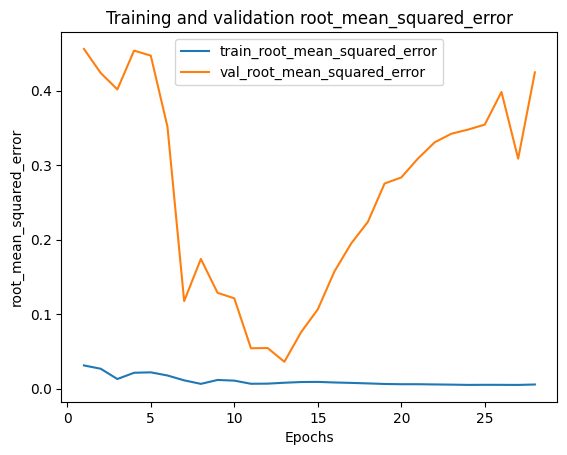

In [ ]:
log = model.fit(
    xTrain,
    yTrain,
    epochs=100,
    batch_size=128,
    validation_split = 0.25,
    verbose=1,
    callbacks=[earlyStopping],
    shuffle=False)
plot_metric(log, 'root_mean_squared_error')

In [ ]:
n_steps = 20

xTest = []
yTest = []

for i in range(n_steps, len(testDataScaled)):
    xTest.append(testDataScaled[i-n_steps:i, 0])
    yTest.append(testDataScaled[i, 0])

xTest, yTest = np.array(xTest), np.array(yTest)
xTest = np.reshape(xTest, (xTest.shape[0], xTest.shape[1], 1))



In [ ]:
predictions = model.predict(xTest) #Prediction on Data using trained model
output = sc.inverse_transform(predictions)
rmse = np.sqrt(mean_squared_error(predictions, yTest)) #Calculating of RMSE
rmse

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step


np.float64(0.2629202102873669)

In [ ]:
eval = model.evaluate(xTest, yTest) #Calculating of additional metrics (Loss, RMSE, MAE)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - loss: 0.0691 - mean_absolute_error: 0.1591 - root_mean_squared_error: 0.2629


The following cells are the joining of the actual data + prediction into a single DF

In [ ]:
df1 = pd.DataFrame(testingData['Close']).astype(float)
df1 = df1.iloc[:-20]
df1 = df1.reset_index(drop=False)

df2 = pd.DataFrame(output, columns = ['Pred Adj Close']).astype(float)


In [ ]:
df2

,Pred Adj Close
0,6.185160
1,6.169440
2,6.146271
3,6.123674
4,6.109543
...,...
1001,98.051987
1002,99.412437
1003,100.761482
1004,102.059883


In [ ]:
df = df1.join(df2)
df = df.set_index('Date')

In [ ]:
df

,NVDA,Pred Adj Close
Date,,
2020-01-02,5.957138,6.185160
2020-01-03,5.861787,6.169440
2020-01-06,5.886370,6.146271
2020-01-07,5.957635,6.123674
2020-01-08,5.968809,6.109543
...,...,...
2023-12-22,48.688877,98.051987
2023-12-26,49.136581,99.412437
2023-12-27,49.274185,100.761482


Results

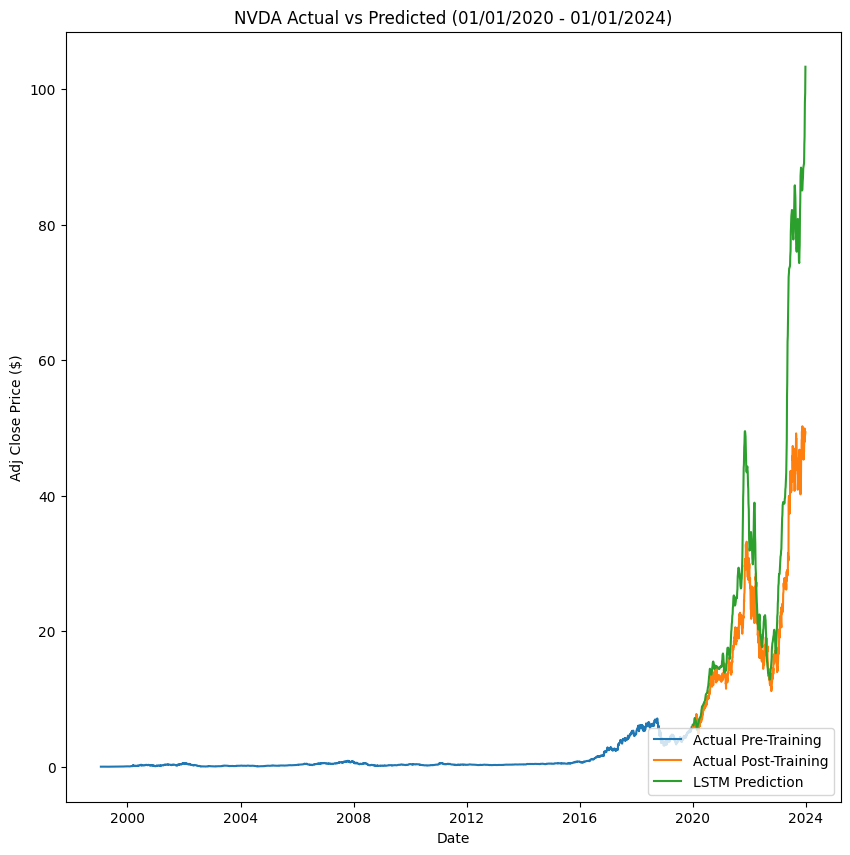

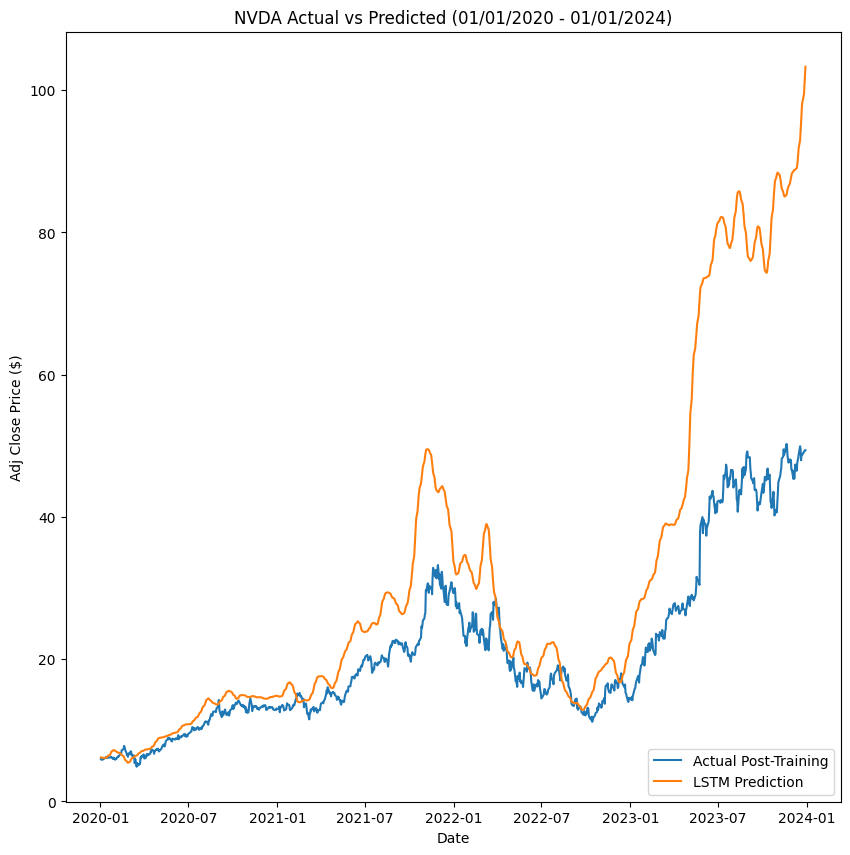

In [ ]:
#plotting of graphs - Full Overview

train = trainingData['Close']
real = df['NVDA']
pred = df['Pred Adj Close']
plt.figure(figsize=(10,10))
plt.title('NVDA Actual vs Predicted (01/01/2020 - 01/01/2024)')
plt.xlabel('Date')
plt.ylabel('Adj Close Price ($)')
plt.plot(train)
plt.plot(real)
plt.plot(pred)
plt.legend(['Actual Pre-Training', 'Actual Post-Training','LSTM Prediction'], loc='lower right')
plt.xticks()
plt.show()

#plotting of graphs - Full Overview
real = df['NVDA']
pred = df['Pred Adj Close']
plt.figure(figsize=(10,10))
plt.title('NVDA Actual vs Predicted (01/01/2020 - 01/01/2024)')
plt.xlabel('Date')
plt.ylabel('Adj Close Price ($)')
plt.plot(real)
plt.plot(pred)
plt.legend(['Actual Post-Training','LSTM Prediction'], loc='lower right')
plt.xticks()
plt.show()